# Script for Zonal Wind Stress Perturbations over a circumpolar current-subpolar gyre system
## Includes Figures 2b, 4, 5, 6b, and pngs for supplemental videos.

In [1]:
import numpy as np
import matplotlib.pylab as plt
import xarray as xr
import os
import pickle

#import sys
import xgcm
from xmitgcm import open_mdsdataset
import MITgcmutils
import matplotlib.ticker as mticker

In [2]:
group_scratch_dir = '/oak/stanford/groups/earlew/nbcoffey'#'/scratch/groups/earlew/nbcoffey'

In [3]:
exp_home_dir = os.path.join(group_scratch_dir, 'research/modeling/MITgcm/experiments')

exp_names = ['shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_year200_layers', 
             'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_incr_wsc_SG_subpolarONLYfixMag_year200_layers',
             'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_wgb_y1375km_year200_layers',
             'shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_contract_fixMag_year200_layers']

# exp_names_alias = ['Ridge+Bumps', '$\\tau_E$ N-shift', '$1.25\,\\tau_W^{\\mathrm{Max}}$', '$\\tau_W$ S-shift']
exp_names_alias = ['Control', '$\\tau_E$ N-shift', '$1.25\,\\tau_W^{\\mathrm{Max}}$', '$\\tau_W$ S-shift']
# exp_names_alias = ['Control', '$1.25\,\\tau_W^{\\mathrm{Max}}$']

In [4]:
run_config = {}
output = {}
prefix_list = ['THETA_inst', 'VVEL_inst', 'UVEL_inst']#, 'ETAN_inst']
# prefix_list = ['UVEL', 'VVEL', 'WVEL', 'THETA',  'UVELTH', 'VVELTH', 'WVELTH', 
#                     'ETAN', 'UVELSQ', 'VVELSQ', 'WVELSQ', 
#                    'TOTTTEND', 'TFLUX', 'ADVr_TH', 'ADVx_TH', 'ADVy_TH', 
#                    'DFrE_TH', 'DFxE_TH', 'DFyE_TH', 'DFrI_TH', 'oceQsw', 'WTHMASS', 
#                   'LaUH1TH', 'LaVH1TH', 'LaHw1TH','LaHs1TH']#, 'ETAN_inst']
# got an issue with Etan at one of these timesteps. Don't love that.
# Could not find the expected file prefixes ['THETA_inst', 'VVEL_inst', 'UVEL_inst', 'ETAN_inst'] 
# at iternum 4.84303e+06. (Instead found ['UVEL_inst', 'THETA_inst', 'VVEL_inst'])

#iters = [80449, 160898, 241347, 321796, 402245, 482694, 563143, 643592, 724041, 804490, 884939]
iters = 'all'
for i,exp_name in enumerate(exp_names):
    print(i)
    
    results_dir = os.path.join(exp_home_dir, exp_name, 'results')

    # load run_config file (saved at the end of the run_config notebook)
    input_dir = os.path.join(exp_home_dir, exp_name, 'input')
    params_fpath = os.path.join(input_dir, 'params.p')
    with open(params_fpath, 'rb') as f:
        run_config[exp_name] = pickle.load(f)
        
    # load model output as an xarray dataset, which is essentially a netcdf file
    output_ds = open_mdsdataset(data_dir=results_dir, prefix=prefix_list, 
                          geometry='cartesian', iters=iters)
    
    output[exp_name] = output_ds

0
1
2
3


In [5]:
output[exp_name]

<xarray.Dataset>
Dimensions:              (XC: 400, XG: 400, YC: 250, YG: 250, Z: 80, Zl: 80, Zp1: 81, Zu: 80, layer_1TH_bounds: 44, layer_1TH_center: 43, layer_1TH_interface: 42)
Coordinates:
  * XC                   (XC) >f4 5e+03 1.5e+04 2.5e+04 ... 3.985e+06 3.995e+06
  * YC                   (YC) >f4 5e+03 1.5e+04 2.5e+04 ... 2.485e+06 2.495e+06
  * XG                   (XG) >f4 0.0 1e+04 2e+04 ... 3.97e+06 3.98e+06 3.99e+06
  * YG                   (YG) >f4 0.0 1e+04 2e+04 ... 2.47e+06 2.48e+06 2.49e+06
  * Z                    (Z) >f4 -3.534 -10.61 -17.68 ... -2.994e+03 -3.065e+03
  * Zp1                  (Zp1) >f4 0.0 -7.069 -14.14 ... -3.03e+03 -3.1e+03
  * Zu                   (Zu) >f4 -7.069 -14.14 -21.22 ... -3.03e+03 -3.1e+03
  * Zl                   (Zl) >f4 0.0 -7.069 -14.14 ... -2.959e+03 -3.03e+03
    rA                   (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxG                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyG                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    Depth                (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAz                  (YG, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxC                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyC                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAw                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAs                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    drC                  (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    drF                  (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefC               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefF               (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    hFacC                (Z, YC, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacW                (Z, YC, XG) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacS                (Z, YG, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskC                (Z, YC, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskW                (Z, YC, XG) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskS                (Z, YG, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    rhoRef               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
  * layer_1TH_bounds     (layer_1TH_bounds) >f4 -1.0 -0.9 -0.8 ... 11.0 12.0
  * layer_1TH_center     (layer_1TH_center) float32 -0.95 -0.85 ... 10.5 11.5
  * layer_1TH_interface  (layer_1TH_interface) >f4 -0.9 -0.8 -0.7 ... 10.0 11.0
Data variables:
    *empty*

In [6]:
# import glob
# import os
# import re

# def get_iterations_with_time_avg_data(data_dir):
#     """Find iterations that have time-averaged (non-_inst) physics variables"""
    
#     # Get all available iterations
#     all_files = glob.glob(os.path.join(data_dir, "*.data"))
#     iterations = set()
#     for f in all_files:
#         match = re.search(r'\.(\d{10})\.data$', os.path.basename(f))
#         if match:
#             iterations.add(int(match.group(1)))
    
#     iterations = sorted(list(iterations))
    
#     # Check each iteration to see if it has time-averaged physics variables
#     time_avg_iterations = []
    
#     for iter_num in iterations:
#         pattern = os.path.join(data_dir, f"*.{iter_num:010d}.data")
#         files = glob.glob(pattern)
#         prefixes = set()
#         for f in files:
#             prefix = os.path.basename(f).split('.')[0]
#             if (not prefix.endswith('_inst') and 
#                 prefix not in ['pickup', 'pickup_somT']):
#                 prefixes.add(prefix)
        
#         # Check if this iteration has good physics variables (not just grid/restart)
# #         physics_indicators = {'TOTTTEND', 'ADVr_TH', 'TFLUX', 'WTHMASS', 'oceQsw'}
#         physics_indicators = {'UVEL'} # THIS IS AN IMPORTANT LINE
#         if any(indicator in prefixes for indicator in physics_indicators):
#             time_avg_iterations.append(iter_num)
#             print(f"Found time-averaged data at iteration {iter_num}: {sorted(list(prefixes))}")
    
#     return time_avg_iterations

# def get_common_prefixes_from_iterations(data_dir, iterations):
#     """Get prefixes common to all specified iterations"""
    
#     iteration_prefixes = []
#     for iter_num in iterations:
#         pattern = os.path.join(data_dir, f"*.{iter_num:010d}.data")
#         files = glob.glob(pattern)
#         prefixes = set()
#         for f in files:
#             prefix = os.path.basename(f).split('.')[0]
#             if (not prefix.endswith('_inst') and 
#                 prefix not in ['pickup', 'pickup_somT']):
#                 prefixes.add(prefix)
#         iteration_prefixes.append(prefixes)
    
#     # Find intersection of all
#     if iteration_prefixes:
#         return sorted(list(set.intersection(*iteration_prefixes)))
#     else:
#         return []

# # load output (time-averaged data)
# run_config_avgs = {}
# avgs = {}

# for i, exp_name in enumerate(exp_names):
#     print(f"Processing experiment {i}: {exp_name}")
    
#     results_dir = os.path.join(exp_home_dir, exp_name, 'results')

#     # load run_config file (saved at the end of the run_config notebook)
#     input_dir = os.path.join(exp_home_dir, exp_name, 'input')
#     params_fpath = os.path.join(input_dir, 'params.p')
#     with open(params_fpath, 'rb') as f:
#         run_config_avgs[exp_name] = pickle.load(f)
    
#     # Find iterations with time-averaged data
#     time_avg_iters = get_iterations_with_time_avg_data(results_dir)
#     print(f"Found {len(time_avg_iters)} iterations with time-averaged data")
    
#     if len(time_avg_iters) == 0:
#         print("No time-averaged iterations found! Skipping...")
#         continue
    
#     # Get common prefixes across these iterations
#     all_time_avg_vars = get_common_prefixes_from_iterations(results_dir, time_avg_iters)
    
#     print(f"Found {len(all_time_avg_vars)} consistently available time-averaged variables:")
#     print(f"{all_time_avg_vars}")
    
#     # Load using specific iterations that have the data
#     avgs_ds = open_mdsdataset(data_dir=results_dir, 
#                              prefix=all_time_avg_vars,
#                              geometry='cartesian', 
#                              iters=time_avg_iters)  # Use specific iterations
    
#     avgs[exp_name] = avgs_ds
#     print(f"Loaded dataset with variables: {list(avgs_ds.data_vars)}")
#     print(f"Time dimension: {len(avgs_ds.time) if 'time' in avgs_ds.dims else 'No time dim'}")
#     print()

In [6]:
# load output that has been averaged over the entire run.
# it is set in the model setup - the averaging window is 50 years since Earle set it to be that. You can go back in and change this, but I am not sure how to change your averaging window in an ad hoc manner.

run_config_avgs = {}
avgs = {}

prefix_list = ['UVEL', 'VVEL', 'WVEL', 'THETA',  'VVELTH', 'UVELTH', 
                    'ETAN', 'UVELSQ', 'VVELSQ', 'WVEL']

# prefix_list = ['UVEL', 'VVEL', 'THETA',  'VVELTH', 'UVELTH']

#iters = [80449, 160898, 241347, 321796, 402245, 482694, 563143, 643592, 724041, 804490, 884939]
iters = 'all'
for i,exp_name in enumerate(exp_names):
    print(f"Processing experiment {i}: {exp_name}")
    
    results_dir = os.path.join(exp_home_dir, exp_name, 'results')

    # load run_config file (saved at the end of the run_config notebook)
    input_dir = os.path.join(exp_home_dir, exp_name, 'input')
    params_fpath = os.path.join(input_dir, 'params.p')
    with open(params_fpath, 'rb') as f:
        run_config_avgs[exp_name] = pickle.load(f)
        
    # load model output as an xarray dataset, which is essentially a netcdf file
    avgs_ds = open_mdsdataset(data_dir=results_dir, prefix=prefix_list, 
                          geometry='cartesian', iters=iters)
    avgs[exp_name] = avgs_ds

Processing experiment 0: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_year200_layers
Processing experiment 1: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_incr_wsc_SG_subpolarONLYfixMag_year200_layers
Processing experiment 2: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_wgb_y1375km_year200_layers
Processing experiment 3: shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_contract_fixMag_year200_layers


In [7]:
avgs[exp_name]

<xarray.Dataset>
Dimensions:              (XC: 400, XG: 400, YC: 250, YG: 250, Z: 80, Zl: 80, Zp1: 81, Zu: 80, layer_1TH_bounds: 44, layer_1TH_center: 43, layer_1TH_interface: 42, time: 31)
Coordinates:
  * XC                   (XC) >f4 5e+03 1.5e+04 2.5e+04 ... 3.985e+06 3.995e+06
  * YC                   (YC) >f4 5e+03 1.5e+04 2.5e+04 ... 2.485e+06 2.495e+06
  * XG                   (XG) >f4 0.0 1e+04 2e+04 ... 3.97e+06 3.98e+06 3.99e+06
  * YG                   (YG) >f4 0.0 1e+04 2e+04 ... 2.47e+06 2.48e+06 2.49e+06
  * Z                    (Z) >f4 -3.534 -10.61 -17.68 ... -2.994e+03 -3.065e+03
  * Zp1                  (Zp1) >f4 0.0 -7.069 -14.14 ... -3.03e+03 -3.1e+03
  * Zu                   (Zu) >f4 -7.069 -14.14 -21.22 ... -3.03e+03 -3.1e+03
  * Zl                   (Zl) >f4 0.0 -7.069 -14.14 ... -2.959e+03 -3.03e+03
    rA                   (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxG                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyG                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    Depth                (YC, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAz                  (YG, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dxC                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    dyC                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAw                  (YC, XG) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    rAs                  (YG, XC) >f4 dask.array<chunksize=(250, 400), meta=np.ndarray>
    drC                  (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    drF                  (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefC               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
    PHrefF               (Zp1) >f4 dask.array<chunksize=(81,), meta=np.ndarray>
    hFacC                (Z, YC, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacW                (Z, YC, XG) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    hFacS                (Z, YG, XC) >f4 dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskC                (Z, YC, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskW                (Z, YC, XG) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    maskS                (Z, YG, XC) bool dask.array<chunksize=(80, 250, 400), meta=np.ndarray>
    rhoRef               (Z) >f4 dask.array<chunksize=(80,), meta=np.ndarray>
  * layer_1TH_bounds     (layer_1TH_bounds) >f4 -1.0 -0.9 -0.8 ... 11.0 12.0
  * layer_1TH_center     (layer_1TH_center) float32 -0.95 -0.85 ... 10.5 11.5
  * layer_1TH_interface  (layer_1TH_interface) >f4 -0.9 -0.8 -0.7 ... 10.0 11.0
    iter                 (time) int64 dask.array<chunksize=(1,), meta=np.ndarray>
  * time                 (time) timedelta64[ns] 74 days 13:34:52 ... 85 days ...
Data variables:
    THETA                (time, Z, YC, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    VVELSQ               (time, Z, YG, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    ETAN                 (time, YC, XC) float32 dask.array<chunksize=(1, 250, 400), meta=np.ndarray>
    UVEL                 (time, Z, YC, XG) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    VVELTH               (time, Z, YG, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    VVEL                 (time, Z, YG, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    WVEL                 (time, Zl, YC, XC) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    UVELSQ               (time, Z, YC, XG) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>
    UVELTH               (time, Z, YC, XG) float32 dask.array<chunksize=(1, 80, 250, 400), meta=np.ndarray>

In [8]:
# create time array using file names

secsInDays = 3600*24
secsInMons = secsInDays*30
secsInYears = secsInDays*365

# time_yrs_dict = {}

for i,exp_name in enumerate(exp_names):
    
    results_dir = os.path.join(exp_home_dir, exp_names[i], 'results')

    
    results_fnames = os.listdir(results_dir)
#     theta_inst_fnames = [fname for fname in results_fnames 
#                          if (fname.startswith('THETA_inst') and fname.endswith('.data'))]


#     # get time stamp info from filenames
#     iters = np.array([int(fname.split('.')[1]) for fname in theta_inst_fnames])
#     iters.sort()
#     #print(iters)

#     mitgcm_params = run_config[exp_name]['mitgcm_params']['data']
#     deltaT = mitgcm_params[2]['deltaT']
#     #print(deltaT)
#     time_secs = iters*deltaT

#     output[exp_name].attrs['time'] = time_secs
    
    # avg ones now
    
    UVELTH_fnames = [fname for fname in results_fnames 
                         if (fname.startswith('UVELTH.') and fname.endswith('.data'))]


    # get time stamp info from filenames
    iters = np.array([int(fname.split('.')[1]) for fname in UVELTH_fnames])
    iters.sort()
    
    mitgcm_params = run_config_avgs[exp_name]['mitgcm_params']['data']
    deltaT = mitgcm_params[2]['deltaT']
    #print(deltaT)
    time_secs_avgs = iters*deltaT

    avgs[exp_name].attrs['time'] = time_secs_avgs

In [9]:
# print("Snapshot vars:", time_secs.max()/secsInYears)
print("Time-avg vars:", time_secs_avgs.max()/secsInYears)

Time-avg vars: 229.9999941019787


In [11]:
# make sure you know what the years mean
print(len(time_secs_avgs/secsInYears))
print((time_secs_avgs/secsInYears))
print((time_secs_avgs))
avgs[exp_names[0]]['time']

31
[199.99998947 201.00000618 201.99999185 203.00000856 203.99999423
 205.00001094 205.99999661 207.00001332 207.99999899 208.99998465
 210.00000136 210.99998703 212.00000374 212.99998941 214.00000612
 214.99999179 216.0000085  216.99999417 218.00001088 218.99999654
 220.00001325 220.99999892 221.99998459 223.0000013  223.99998697
 225.00000368 225.99998935 227.00000606 227.99999172 229.00000843
 229.9999941 ]
[6.30719967e+09 6.33873620e+09 6.37027174e+09 6.40180827e+09
 6.43334382e+09 6.46488034e+09 6.49641589e+09 6.52795242e+09
 6.55948797e+09 6.59102352e+09 6.62256004e+09 6.65409559e+09
 6.68563212e+09 6.71716767e+09 6.74870419e+09 6.78023974e+09
 6.81177627e+09 6.84331182e+09 6.87484834e+09 6.90638389e+09
 6.93792042e+09 6.96945597e+09 7.00099151e+09 7.03252804e+09
 7.06406359e+09 7.09560012e+09 7.12713566e+09 7.15867219e+09
 7.19020774e+09 7.22174427e+09 7.25327981e+09]


<xarray.DataArray 'time' (time: 31)>
array([6442492000000000, 6474705000000000, 6506917000000000, 6539130000000000,
       6571342000000000, 6603555000000000, 6635767000000000, 6667980000000000,
       6700192000000000, 6732404000000000, 6764617000000000, 6796829000000000,
       6829042000000000, 6861254000000000, 6893467000000000, 6925679000000000,
       6957892000000000, 6990104000000000, 7022317000000000, 7054529000000000,
       7086742000000000, 7118954000000000, 7151166000000000, 7183379000000000,
       7215591000000000, 7247804000000000, 7280016000000000, 7312229000000000,
       7344441000000000, 7376654000000000, 7408866000000000],
      dtype='timedelta64[ns]')
Coordinates:
    iter     (time) int64 dask.array<chunksize=(1,), meta=np.ndarray>
  * time     (time) timedelta64[ns] 74 days 13:34:52 ... 85 days 18:01:06
Attributes:
    standard_name:  time
    long_name:      Time
    axis:           T
    calendar:       gregorian

# Figure 2 b) Bathymetry

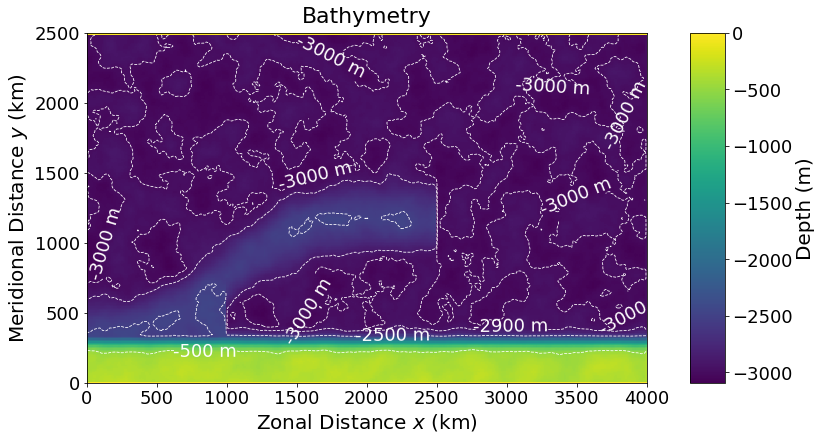

In [12]:
# import matplotlib.pyplot as plt
# import numpy as np
fz=18+2
# --- 1. pull the data out of the xarray.Dataset -----------------------------
ds     = avgs[exp_name]            # your dataset
depth  = ds.Depth.load().values    # 2-D NumPy array (YC, XC) — forces into memory
x_km   = ds.XC.values / 1_000.0    # convert metres → km
y_km   = ds.YC.values / 1_000.0

# --- 2. build a meshgrid for pcolormesh -------------------------------------
#    (XC, YC) are 1-D, so we need 2-D grids of the same shape as depth
xx, yy = np.meshgrid(x_km, y_km)

# --- 3. create the plot ------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

cmap = plt.get_cmap('viridis')     # _r reverses so shallow = light, deep = dark
# pcm  = ax.pcolormesh(xx, yy, -depth,
#                      cmap=cmap,
#                      shading='auto',
#                      vmin=np.nanmin(-depth),
#                      vmax=0)       # force 0 at the top of colour-scale
# tell matplotlib to draw the colour‐shaded cells as one raster image
pcm = ax.pcolormesh(xx, yy, -depth,
                     cmap=cmap,
                     shading='auto',
                     vmin=np.nanmin(-depth),
                     vmax=0,
                    rasterized=True)          # <── key line


# Optional: add one or two isobaths for visual structure
# cont = ax.contour(x_km, y_km, -depth,
#                   levels=[-3000, -2900, -2500, -500],
#                   colors='w', linestyles='--', linewidths=0.8)
# Copy the depth data and set the northern boundary row to NaN
depth_for_contour = np.copy(-depth)
depth_for_contour[-1, :] = np.nan

cont = ax.contour(x_km, y_km, depth_for_contour,
                  levels=[-3000, -2900, -2500, -500],
                  colors='w', linestyles='--', linewidths=0.8)

ax.clabel(cont, fmt='%d m', fontsize=fz-2, colors='w')

# colourbar
cbar = fig.colorbar(pcm, ax=ax, pad=0.02)  # make the bar
cbar.ax.tick_params(labelsize=fz-2)          # enlarge its tick labels
cbar.set_label('Depth (m)', fontsize=fz)

# axis labels & title
ax.set_xlabel('Zonal Distance $x$ (km)', fontsize=fz)
ax.set_ylabel('Meridional Distance $y$ (km)', fontsize=fz)
ax.set_title('Bathymetry', fontsize=fz+2, pad=10)

# nicer tick labels
ax.tick_params(axis='both', which='major', labelsize=fz-2)
# cbar.ax.tick_params(labelsize=12)

# optional: equal aspect so pixels look square (comment out if domain is long & thin)
ax.set_aspect('equal', adjustable='box')

fig.savefig('v1_bathy_ramp2ridge_noise100_noMR_check.pdf',
            dpi=300,            # resolution of that single raster panel
            bbox_inches='tight',
            facecolor='white',  # solid background
            transparent=False)

plt.show()

# Figure 6 b) MHT 

Time-mean years 0 to 10 shown in the plot

In [11]:
import os

# Create output directory
output_dir = 'all_mht_years_v1'
os.makedirs(output_dir, exist_ok=True)

fz       = 20
tick_sz  = 18

tidxequil = 0#-10 # if using 5-year t-avg'd vars, starting at t-avgd year 155 (-10)

Lx = 4000*1e3 # meters.

rho = 1025 # kg/m3
c_w = 4100 # J/C/kg

# Define a color map to ensure consistent colors for the same terms across experiments
colors = {
    'vT': 'k',
    'vT_xtmean': 'b',
    'vT_tmean': 'g',
    'vT_eddy': 'r'
}

# Define linestyles for each experiment
linestyles = ['-', '--', '-.', ':', (0, (3, 1, 1, 1)), (0, (5, 2, 1, 2))]  # Add more if needed

# Loop through each year
for year_offset in range(11):  # 0 through 8
    tidx = tidxequil + year_offset
    
    fig, ax = plt.subplots(figsize=(8, 6.9), constrained_layout=True)
    
    for i, exp_name in enumerate(exp_names):
        
        # Reset tidxequil and recalculate tidx for each experiment
        tidxequil = 0#-10
        tidx = tidxequil + year_offset

        # No need to set the current axis since we have only one plot now
        grid = xgcm.Grid(avgs[exp_name], periodic=['X'])

        ds = avgs[exp_name]
        theta_avg = ds['THETA']
        theta_min = theta_avg.min()

        v_transport = ds.VVEL * ds.dxG * ds.hFacS * ds.drF
        vT_transport = ds.VVELTH * ds.dxG * ds.hFacS * ds.drF

        v_transport_intp = grid.interp(v_transport,'Y', boundary='extend')
        vT_intp = grid.interp(vT_transport, 'Y', boundary='extend')

        vT_mean_xzint = ((ds.THETA-theta_min)*v_transport_intp).sum(dim=['Z', 'XC']) # mean in x, no decomp
        vT_total_xzint = (vT_intp-v_transport_intp*theta_min).sum(dim=['Z', 'XC']) # total
        vT_prime_xzint  = vT_total_xzint - vT_mean_xzint

        # this is moc
        vT_bracketmean_xzint = ((ds.THETA.mean(dim='XC') - theta_min) * v_transport_intp.sum(dim='XC')).sum(dim=['Z']) # multiply by Lx with v_tr_in.sum instead of mean.
        vT_starmean_xzint = vT_mean_xzint - vT_bracketmean_xzint # GE

        mht_mean = rho*c_w*vT_mean_xzint*1e-15
        mht_total = rho*c_w*vT_total_xzint*1e-15
        mht_eddy = rho*c_w*vT_prime_xzint*1e-15

        mht_bracketmean = rho*c_w*vT_bracketmean_xzint*1e-15
        mht_starmean = rho*c_w*vT_starmean_xzint*1e-15

        t_years = ds.attrs['time']/secsInYears

        # Get linestyle for this experiment
        linestyle = linestyles[i % len(linestyles)]  # Cycle through if more experiments than linestyles
        
        # Get label from exp_names_alias
        label_base = exp_names_alias[i]

        # Plot each term with consistent colors - averaging from tidxequil to tidx
        plt.plot(mht_total[tidxequil:tidx+1].mean(dim='time'), ds.YC/1e3, color=colors['vT'], label=f'{label_base}  Total', lw=2, linestyle=linestyle)
        plt.plot(mht_bracketmean[tidxequil:tidx+1].mean(dim='time'), ds.YC/1e3, color=colors['vT_xtmean'], label=f'{label_base}  Eulerian MOC', lw=2, linestyle=linestyle)
        plt.plot(mht_starmean[tidxequil:tidx+1].mean(dim='time'), ds.YC/1e3, color=colors['vT_tmean'], label=f'{label_base}  Gyres & Standing Eddies', lw=2, linestyle=linestyle)
        plt.plot(mht_eddy[tidxequil:tidx+1].mean(dim='time'), ds.YC/1e3, color=colors['vT_eddy'], label=f'{label_base}  Transient Eddies', lw=2, linestyle=linestyle)

    # SWAPPED AXIS LABELS AND LIMITS
    ax.set_ylabel('Meridional Distance  $y$  (km)', fontsize=fz)
    ax.set_xlabel('Meridional Heat Transport  (PW)', fontsize=fz)
    ax.set_xlim(-0.15, 0.15)
    ax.set_ylim(0, 2500)
    ax.grid(True, alpha=0.3)
    ax.axvline(0, ls='-.', c='0.5')

    # integer axis ticks
    import matplotlib.ticker as mticker
    int_fmt = mticker.FormatStrFormatter('%.1f')
    ax.tick_params(axis='both', which='major', labelsize=tick_sz)

    # ---------------------------------------------------------------
    #  TWO NON-OVERLAPPING LEGENDS
    # ---------------------------------------------------------------
    from matplotlib.lines import Line2D

    # 1) Experiment legend: dynamically create based on number of experiments
    exp_handles = []
    for i, alias in enumerate(exp_names_alias):
        exp_handles.append(
            Line2D([], [], color='k', lw=2, ls=linestyles[i % len(linestyles)], label=alias)
        )
    
    leg_exp = ax.legend(handles=exp_handles, 
                        loc='lower right', fontsize=fz-2, frameon=False, handlelength=1.5)
    ax.add_artist(leg_exp)

    # 2) Term legend: colour encodes physical term
    term_handles = [
        Line2D([], [], color=colors['vT'],        lw=2, label='Total'),
        Line2D([], [], color=colors['vT_xtmean'], lw=2, label='Eulerian MOC'),
        Line2D([], [], color=colors['vT_tmean'],  lw=2, label='Gyres & Meanders'),
        Line2D([], [], color=colors['vT_eddy'],   lw=2, label='Transient Eddies')
    ]
    leg_term = ax.legend(handles=term_handles, 
                         loc='lower left', fontsize=fz-2, frameon=False, handlelength=1.5)

#     fig.suptitle(f'Meridional Heat Transport (Years {tidxequil+11} to {tidx+11})', fontsize=fz+2)
    fig.suptitle(f'Meridional Heat Transport (Years {tidxequil} to {tidx})', fontsize=fz+2)

    # Save figure
    filename = f'mht_profile_all_year_{year_offset:02d}.pdf'
    filepath = os.path.join(output_dir, filename)
    fig.savefig(filepath, dpi=300, bbox_inches='tight', facecolor='white')
    
    plt.close(fig)  # Close figure to free memory
    print(f'Saved: {filepath}')

print(f'\nAll figures saved to {output_dir}/')

Saved: all_mht_years_v1/mht_profile_all_year_00.pdf
Saved: all_mht_years_v1/mht_profile_all_year_01.pdf
Saved: all_mht_years_v1/mht_profile_all_year_02.pdf
Saved: all_mht_years_v1/mht_profile_all_year_03.pdf
Saved: all_mht_years_v1/mht_profile_all_year_04.pdf
Saved: all_mht_years_v1/mht_profile_all_year_05.pdf
Saved: all_mht_years_v1/mht_profile_all_year_06.pdf
Saved: all_mht_years_v1/mht_profile_all_year_07.pdf
Saved: all_mht_years_v1/mht_profile_all_year_08.pdf
Saved: all_mht_years_v1/mht_profile_all_year_09.pdf
Saved: all_mht_years_v1/mht_profile_all_year_10.pdf

All figures saved to all_mht_years_v1/


# Figure 3 c), e), g)

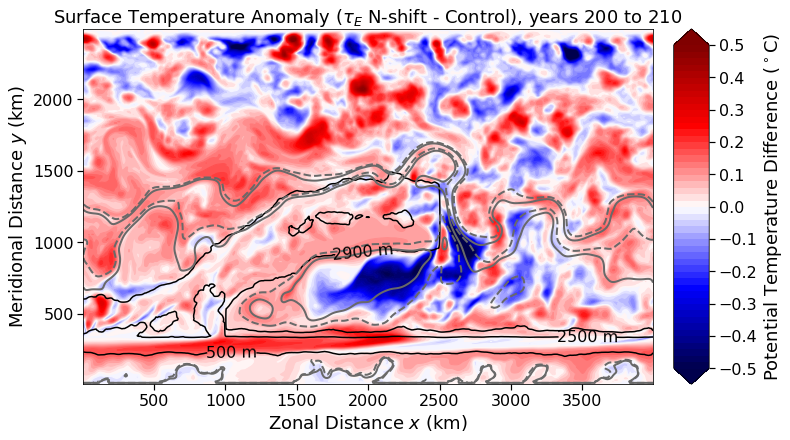

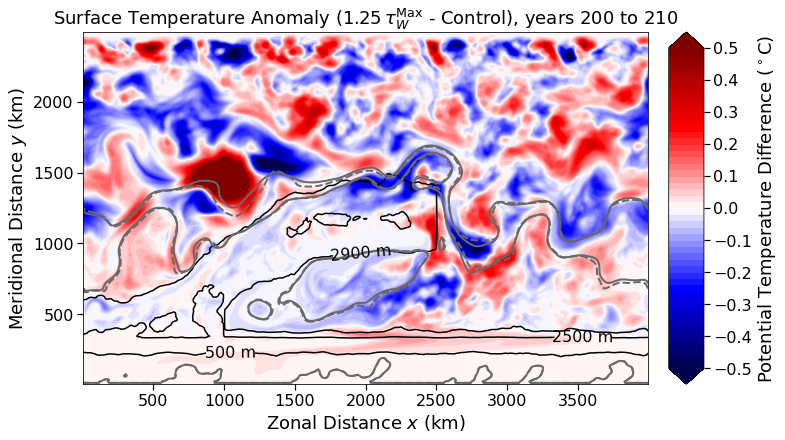

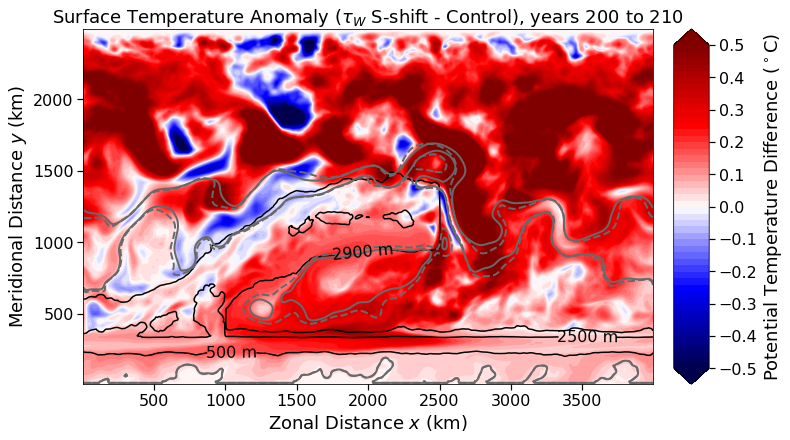

In [13]:
import matplotlib.ticker as mticker
fz=18

tavgvars = True

vble = 'THETA'
if tavgvars:
    tidxequil = 1#-10
    tidx = tidxequil+9
else:
    tidx = -1
zidx = 0

# Updated color levels for temperature difference
clvls = np.arange(-0.5, 0.51, 0.02)
dep_lvls = [500, 2500, 2900]

# Store control experiment data
control_data = {}

for i, exp_name in enumerate(exp_names):
    # Process variable data
    if tavgvars:
        ds = avgs[exp_name]
        vble_map = ds[vble][tidxequil:tidx, 0, :, :]  # 0 index for surface layer
        vble_map = vble_map.mean(dim='time')
        vble_map.attrs = ds[vble].attrs
    else:
        ds = output[exp_name]
        vble_map = ds[vble][tidx, zidx, :, :]
    
    x = ds['XC']/1e3
    y = ds['YC']/1e3
    z = ds['Z'].values
    
    # Calculate streamfunction for all experiments
    grid = xgcm.Grid(ds, periodic=['X'])
    u_bt = (ds.UVEL * ds.hFacW * ds.drF).sum(dim='Z')
    v_bt = (ds.VVEL * ds.hFacS * ds.drF).sum(dim='Z')
    psi = grid.cumsum(-u_bt * ds.dyG, 'Y', boundary='fill')
    psi_mean = psi[tidxequil:tidx, :, :].mean('time')/1e6
    
    if i == 0:
        # Store control experiment data
        control_data = {
            'vble_map': vble_map,
            'psi': psi_mean,
            'x': x,
            'y': y,
            'z': z,
            'ds': ds
        }
        continue  # Skip plotting for control experiment
    
    # For perturbation experiments, create difference plot
    fig, axes = plt.subplots(figsize=(12, 6), constrained_layout=True)
    
    # Calculate differences
    vble_diff = vble_map - control_data['vble_map']
    
    cmap = 'seismic'
    
    # Plot the difference
    im = plt.contourf(x, y, vble_diff, clvls, vmin=clvls.min(), vmax=clvls.max(), 
                     cmap=cmap, extend='both', antialiased=True)
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
#     # Add bathymetry contours
#     CS = plt.contour(x, y, ds.Depth, dep_lvls, colors='k')
#     plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    # Add bathymetry contours (excluding the northern boundary)
    depth_for_contour = np.copy(ds.Depth)
    depth_for_contour[-1, :] = np.nan

    CS = plt.contour(x, y, depth_for_contour, dep_lvls, colors='k')
    plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    
    # Add streamfunction contours
    psi_lvl = 30
    CS0 = plt.contour(control_data['x'], control_data['y'], control_data['psi'], 
                     levels=[-psi_lvl, 0, psi_lvl], colors='dimgray', linestyles='-', linewidths=2)
    CS1 = plt.contour(x, y, psi_mean, levels=[-psi_lvl, 0, psi_lvl], 
                     colors='dimgray', linestyles='--', linewidths=2)
#     plt.clabel(CS0, inline=True, fontsize=fz-2, fmt='%d Sv')
    # Label only the solid/control contours, then move those labels northward.
    # x and y are in km, so 50 means a 50-km displacement.
#     label_dy = 75

#     labels0 = axes.clabel(CS0, inline=False, fontsize=fz-2, fmt='%d Sv')

#     for label in labels0:
#         x_label, y_label = label.get_position()
#         label.set_position((x_label, y_label + label_dy))

    plt.ylabel("Meridional Distance $y$ (km)", fontsize=fz)
    plt.xlabel("Zonal Distance $x$ (km)", fontsize=fz)
    
    tstmp1 = ds.attrs['time'][tidxequil]/secsInYears
    tstmp2 = ds.attrs['time'][tidx]/secsInYears
    plt.title(f"Surface Temperature Anomaly ({exp_names_alias[i]} - {exp_names_alias[0]}), years $%.0f$ to $%.0f$" %(tstmp1-1, tstmp2), fontsize=fz)
    
    cb = plt.colorbar(im, ticks=np.arange(-0.5, 0.51, 0.1))
    cb.set_label('Potential Temperature Difference ($^\circ$C)', fontsize=fz)
    
    axes.set_aspect('equal', adjustable='box')
    axes.xaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))
    axes.yaxis.set_major_formatter(mticker.FormatStrFormatter('%d'))
    axes.tick_params(axis='both', which='major', labelsize=fz-2, length=6, width=1.2)
    cb.ax.tick_params(axis='y', which='major', labelsize=fz-2, length=6, width=1.2)

    # Save with experiment-specific filename
    fig.savefig(f'v1_nolabel_noNbound_{exp_name}_difference_THETA_bathy_baropsi_surface.pdf',
                dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
    
    plt.show()

# Figure 3 d), f), h)

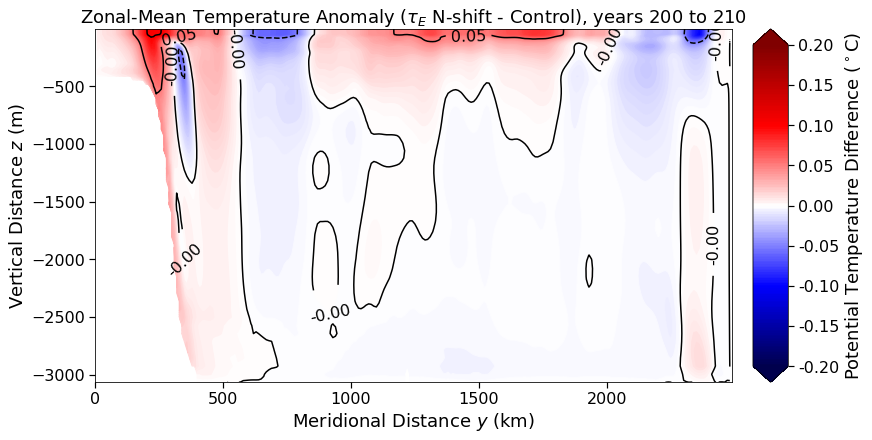

Max absolute difference for shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_incr_wsc_SG_subpolarONLYfixMag_year200_layers: 0.10469532012939453


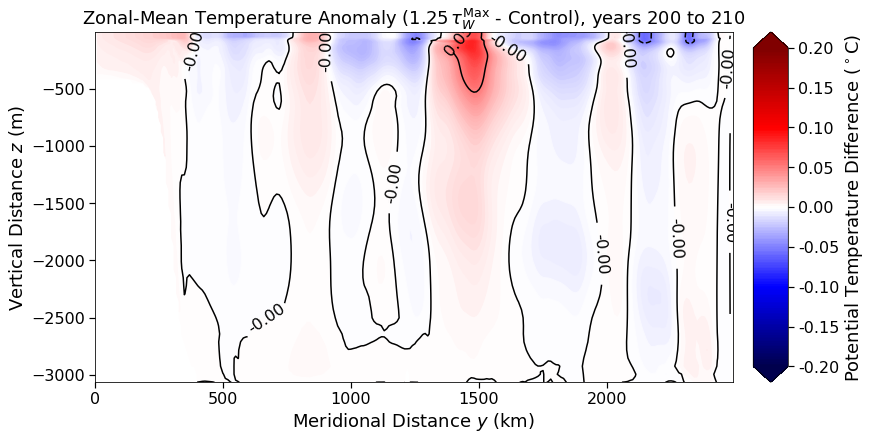

Max absolute difference for shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_25pct_wgb_y1375km_year200_layers: 0.08785629272460938


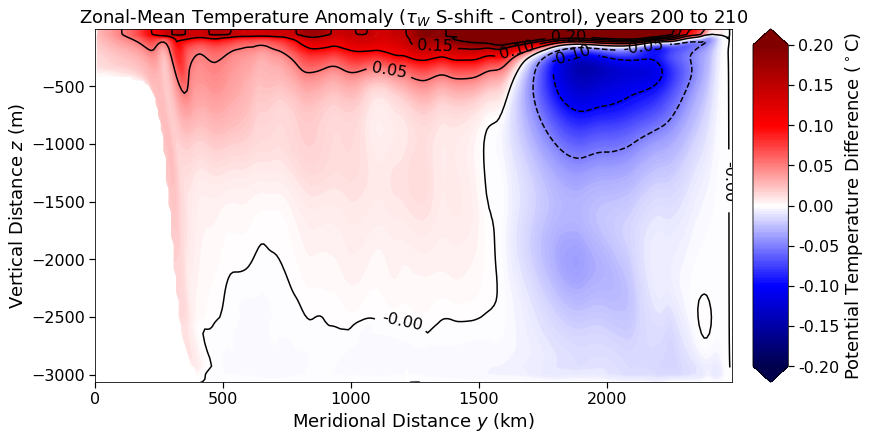

Max absolute difference for shelf_drake500_ramp2ridge500_nocontinent_noise100_noMR_H3km_v02_noaabw_fixZR_80Nz_rerun_branch01_contract_fixMag_year200_layers: 0.44548797607421875


In [9]:
import matplotlib.ticker as mticker

fz = 18  # Font size
vble = 'THETA'
xs1 = 0#1000e3
xs2 = -1#2500e3

# Store control experiment data
control_data = {}

for i, exp_name in enumerate(exp_names):
    ds = avgs[exp_name]
    
    # Set time indices
    tidxequil = -30
    tidx = tidxequil + 9
    
    # Get the data for this experiment and actual coordinate values
    xs1_coord = ds['XC'].isel(XC=xs1).values if xs1 == 0 else xs1
    xs2_coord = ds['XC'].isel(XC=xs2).values if xs2 == -1 else xs2
    vble_sect = ds[vble][tidxequil:tidx, :, :, :].sel(XC=slice(xs1_coord, xs2_coord)).mean(dim='XC').mean(dim='time')
    vble_sect = vble_sect.where(vble_sect!=0)
    units = ds[vble].units
    
    if i == 0:
        # Store control experiment data
        control_data = {
            'vble_sect': vble_sect,
            'y': ds['YG']/1e3,
            'z': ds['Z'].values,
            'tstmp1': ds.attrs['time'][tidxequil]/secsInYears,
            'tstmp2': ds.attrs['time'][tidx]/secsInYears,
            'units': units
        }
        continue  # Skip plotting for control experiment
    
    # For perturbation experiments, create difference plot
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)  # Same size as above
    
    # Interpolate perturbation data to control grid and calculate difference
    vble_sect_interp = vble_sect.interp(Z=control_data['z'])
    vble_sect_diff = vble_sect_interp - control_data['vble_sect']
    
    y = control_data['y']
    z = control_data['z']
    
    # Plotting the difference with high-quality styling
    clvls = np.linspace(-0.20, 0.20, 201)  # 201 levels for very smooth gradient
    cmap = 'seismic'
    
    im = plt.contourf(y, z, vble_sect_diff, clvls, vmin=-0.2, vmax=0.2, 
                     cmap=cmap, extend='both', antialiased=True)
    # Make edges smooth
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
    # Use fewer contour lines for the black contours to avoid overcrowding
    contour_lvls = np.arange(-0.20, 0.201, 0.05)  # Contour every 0.05
    cs = plt.contour(y, z, vble_sect_diff, contour_lvls, colors='k')
    plt.clabel(cs, cs.levels, inline=True, fontsize=fz-2, fmt='%.2f')
    
    # Add labels with proper formatting (CHANGED)
    plt.ylabel("Vertical Distance $z$ (m)", fontsize=fz)
    plt.xlabel("Meridional Distance $y$ (km)", fontsize=fz)
    
    # Updated title with experiment alias and proper formatting
    plt.title("Zonal-Mean Temperature Anomaly (%s - %s), years %.0f to %.0f" %
              (exp_names_alias[i], exp_names_alias[0], 
               control_data['tstmp1']-1, control_data['tstmp2']), fontsize=fz)
    
    # Define specific tick values for the colorbar
    tick_values = np.array([-0.2, -0.15, -0.1, -0.05, 0, 0.05, 0.1, 0.15, 0.2])
    
    # Add colorbar with custom ticks (CHANGED)
    cbar = fig.colorbar(im, ax=ax, orientation='vertical', ticks=tick_values)
    cbar.set_label('Potential Temperature Difference ($^\circ$C)', fontsize=fz)
    
    # Apply formatting to axes and ticks
    int_fmt = mticker.FormatStrFormatter('%.0f')
    
    ax.tick_params(axis='both', which='major',
                   labelsize=fz-2,
                   length=6, width=1.2)
    
    # Format colorbar ticks
    cbar.ax.tick_params(axis='y', which='major',
                        labelsize=fz-2,
                        length=6, width=1.2)
    
    # Optional: format the colorbar tick labels with the desired precision
    cbar.ax.set_yticklabels([f'{val:.2f}' for val in tick_values])
    
    # Save with experiment-specific filename
    fig.savefig(f'THETA_difference_{exp_names_alias[i]}_section_{xs1}_{xs2}.pdf',
                dpi=300,
                bbox_inches='tight',
                facecolor='white',
                transparent=False)
    
    plt.show()
    print(f"Max absolute difference for {exp_name}: {np.nanmax(np.abs(vble_sect_diff.values))}")

# Figure 4 a)

/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:69: UserWarning: linewidths is ignored by contourf


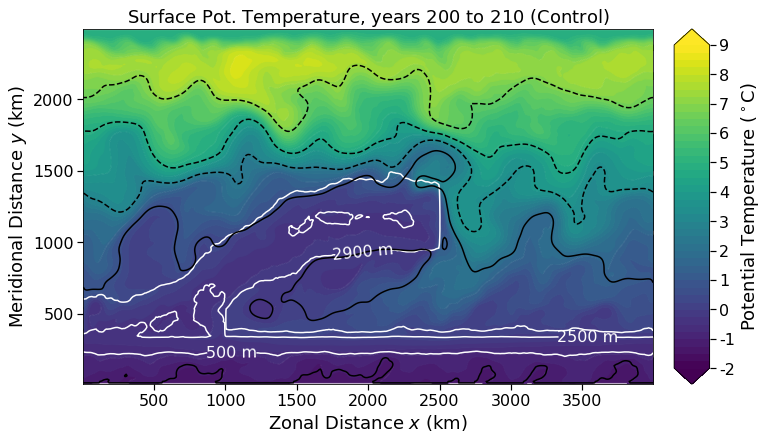

In [14]:
# 10 years, 30 Sv

import matplotlib.ticker as mticker

# put those barotropic streamlines on top of potential temperature
fz=18

tavgvars = True

vble = 'THETA'
if tavgvars:
#     tidxequil = -10 # end of sim plot, use -2
    tidxequil = -30 # for - MR run
    tidx = tidxequil+9
else:
    tidx = -1
zidx = 0

clvls = np.arange(-2.0, 9.1, 0.25)
dep_lvls = [500, 2500, 2900]

# Loop through all experiments
for i, exp_name in enumerate(exp_names):
    if i>0:
        break
    # Create a new figure for each experiment
    fig, axes = plt.subplots(figsize=(12, 6), constrained_layout=True)
    
    if tavgvars:
        ds = avgs[exp_name]
        # Select only the surface layer (topmost Z level)
        vble_map = ds[vble][tidxequil:tidx, 0, :, :]  # 0 index for surface layer
        # Average over time
        vble_map = vble_map.mean(dim='time')
        vble_map.attrs = ds[vble].attrs
    else:
        ds = output[exp_name]
        vble_map = ds[vble][tidx, zidx, :, :]
    
    x = ds['XC']/1e3
    y = ds['YC']/1e3
    z = ds['Z'].values
    
    # Calculate streamfunction
    grid = xgcm.Grid(ds, periodic=['X'])
    u_bt = (ds.UVEL * ds.hFacW * ds.drF).sum(dim='Z')
    v_bt = (ds.VVEL * ds.hFacS * ds.drF).sum(dim='Z')
    psi = grid.cumsum(-u_bt * ds.dyG, 'Y', boundary='fill')
    psi_mean = psi[tidxequil:tidx, :, :].mean('time')/1e6
    
#     # Automatically determine streamfunction contour spacing
#     psi_max = np.abs(psi_mean).max()
#     if psi_max > 150:
#         psi_spacing = 50
#     else:
#         psi_spacing = 10
    
#     # Create appropriate range based on the maximum value and spacing
#     psi_range = int(np.ceil(psi_max / psi_spacing) * psi_spacing)
#     psi_lvls = np.arange(-psi_range, psi_range + 1, psi_spacing)
    psi_lvls = [-150, -100, -50, 0, 30]
    
    vble_map = vble_map.where(vble_map!=0)
    units = vble_map.units
    cmap = 'viridis'

    # Create contour plot
    im = plt.contourf(x, y, vble_map, clvls, vmin=clvls.min(), vmax=clvls.max(), 
                     cmap=cmap, extend='both', antialiased=True, linewidths=0)
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
#     # Add bathymetry contours
#     CS = plt.contour(x, y, ds.Depth, dep_lvls, colors='w')
#     plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    # Add bathymetry contours (excluding the northern boundary)
    depth_for_contour = np.copy(ds.Depth)
    depth_for_contour[-1, :] = np.nan

    CS = plt.contour(x, y, depth_for_contour, dep_lvls, colors='w')
    plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
    
    # Add streamfunction contours with adaptive spacing
    CS2 = plt.contour(x, y, psi_mean, psi_lvls, colors='k')
#     plt.clabel(CS2, inline=True, fontsize=fz-2, fmt='%d Sv')

    plt.ylabel("Meridional Distance $y$ (km)", fontsize=fz)
    plt.xlabel("Zonal Distance $x$ (km)", fontsize=fz)

    if tavgvars:
        tstmp1 = ds.attrs['time'][tidxequil]/secsInYears
        tstmp2 = ds.attrs['time'][tidx]/secsInYears
        # Use exp_names_alias[i] in the title
        plt.title("Surface Pot. Temperature, years $%.0f$ to $%.0f$ (%s)" %(tstmp1-1, tstmp2, exp_names_alias[i]), fontsize=fz)
    else:
        tstmp = ds.attrs['time'][tidx]/secsInYears
        plt.title("%s at $z=%.2f$ m, snapshot $t=%.2f$ years (%s)" %(vble, z[zidx], tstmp, exp_names_alias[i]), fontsize=fz)
    
    cb = plt.colorbar(im)
    cb.set_label('Potential Temperature ($^\circ$C)', fontsize=fz)

    axes.set_aspect('equal', adjustable='box')

    # Format axes
    int_fmt = mticker.FormatStrFormatter('%.0f')
    axes.xaxis.set_major_formatter(int_fmt)
    axes.yaxis.set_major_formatter(int_fmt)
    axes.tick_params(axis='both', which='major', labelsize=fz-2, length=6, width=1.2)

    # Format colorbar
    cb.set_ticks(range(-2, 10))  # For every integer from -2 to 9
    cb.ax.yaxis.set_major_formatter(int_fmt)
    cb.ax.tick_params(axis='y', which='major', labelsize=fz-2, length=6, width=1.2)

    # Save with experiment-specific filename
    fig.savefig(f'v1_nolabel_noNbound_{exp_names_alias[i]}_THETA_bathy_baropsi_fixZR_80Nz_rerun_surf_over{-1*tidxequil}years.pdf',
                dpi=300, bbox_inches='tight', facecolor='white', transparent=False)

    plt.show()

# Figure 4 b)

The other figures generated are not included in the manuscript

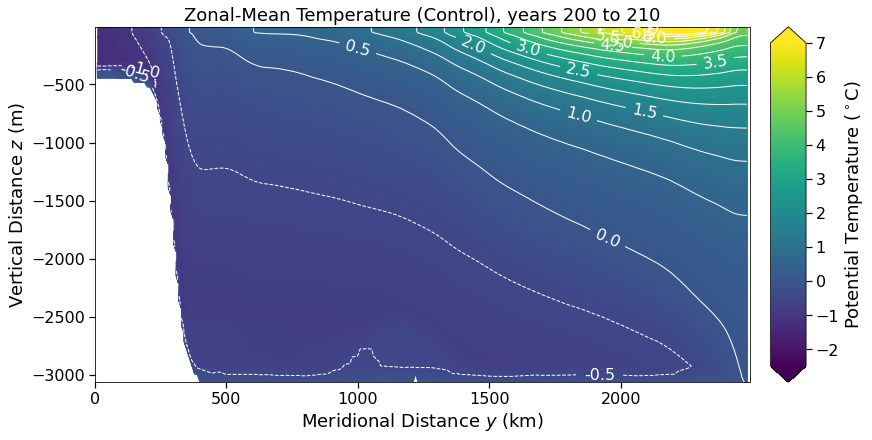

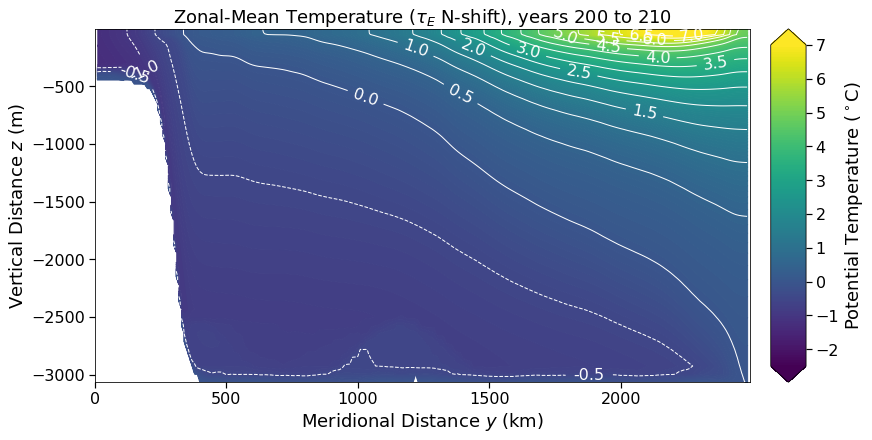

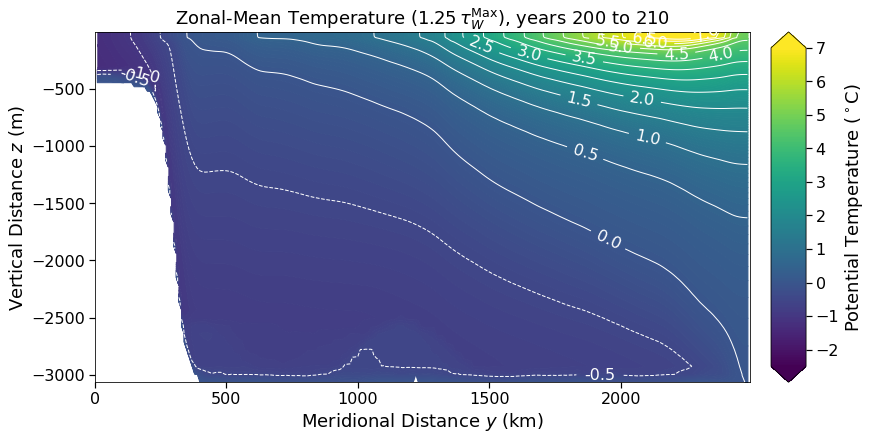

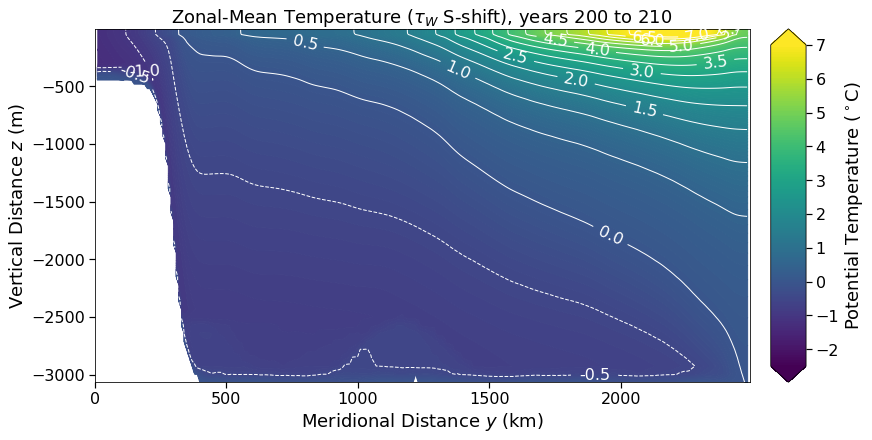

In [14]:
import matplotlib.ticker as mticker

fz = 18  # Font size
vble = 'THETA'
#     tidxequil = -10 # end of sim plot, use -2
tidxequil = -30 # for - MR runtidx = tidxequil + 9
xs1 = 0  # 1000e3
xs2 = -1  # 2500e3

# Loop through all experiments to create control plots
for i, exp_name in enumerate(exp_names):
    # Create a new figure for each experiment
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)  # Same size as anomaly code
    
    # Process data for current experiment
    ds = avgs[exp_name]
    
    # Get the data for this experiment and actual coordinate values
    xs1_coord = ds['XC'].isel(XC=xs1).values if xs1 == 0 else xs1
    xs2_coord = ds['XC'].isel(XC=xs2).values if xs2 == -1 else xs2
    vble_sect = ds[vble][tidxequil:tidx, :, :, :].sel(XC=slice(xs1_coord, xs2_coord)).mean(dim='XC').mean(dim='time')
    vble_sect = vble_sect.where(vble_sect != 0)
    
    units = ds[vble].units
    y = ds['YG']/1e3
    z = ds['Z'].values
    tstmp1 = ds.attrs['time'][tidxequil]/secsInYears
    tstmp2 = ds.attrs['time'][tidx]/secsInYears
    
    # Plot the experiment with high-quality styling (matching anomaly code)
    clvls = np.arange(-2.5, 7.01, 0.05)  # Fine levels for smooth gradient
    cmap = 'viridis'
    
    im = plt.contourf(y, z, vble_sect, clvls,
                     vmin=clvls.min(), vmax=clvls.max(),
                     cmap=cmap, extend='both', antialiased=True)
    
    # Make edges smooth (matching anomaly code)
    for col in im.collections:
        col.set_edgecolor('face')
        col.set_rasterized(True)
    
    # Add temperature contours every 0.5°C
    temp_contours = np.arange(-2.0, 7.5, 0.5)  # Every 0.5°C
    cs = plt.contour(y, z, vble_sect, temp_contours, colors='w', linewidths=1)
    
    # Format contour labels to 1 decimal place
    fmt = lambda x: f'{x:.1f}'
    plt.clabel(cs, cs.levels, inline=True, fontsize=fz-2, fmt=fmt)
    
    # Add labels with proper formatting (SAME AS ANOMALY CODE)
    plt.ylabel("Vertical Distance $z$ (m)", fontsize=fz)
    plt.xlabel("Meridional Distance $y$ (km)", fontsize=fz)
    
    # Title with experiment alias and proper formatting (matching anomaly style)
    plt.title("Zonal-Mean Temperature (%s), years %.0f to %.0f" %
              (exp_names_alias[i], tstmp1-1, tstmp2), fontsize=fz)
    
    # Add colorbar (SAME FORMATTING AS ANOMALY CODE)
    cbar = fig.colorbar(im, ax=ax, orientation='vertical')
    cbar.set_label('Potential Temperature ($^\circ$C)', fontsize=fz)
    
    # Apply formatting to axes and ticks (SAME AS ANOMALY CODE)
    int_fmt = mticker.FormatStrFormatter('%.0f')
    
    ax.tick_params(axis='both', which='major',
                   labelsize=fz-2,
                   length=6, width=1.2)
    
    # Format colorbar ticks (SAME AS ANOMALY CODE)
    cbar.ax.tick_params(axis='y', which='major',
                        labelsize=fz-2,
                        length=6, width=1.2)
    
    # Save the figure with experiment-specific filename (matching pattern)
    fig.savefig(f'THETA_control_{exp_names_alias[i]}_section_{xs1}_{xs2}_over{-1*tidxequil}years.pdf',
                dpi=300,
                bbox_inches='tight',
                facecolor='white',
                transparent=False)
    
    plt.show()

# Supplemental .png files for movies

Movies are located on Zenodo: https://doi.org/10.5281/zenodo.22048640

In [ ]:
from matplotlib import colors as mcolors
import os
import matplotlib.pyplot as plt
import numpy as np
import glob

plt.rcParams['text.usetex'] = False
plt.rcParams['mathtext.fontset'] = 'cm'  # or 'stix'
plt.rcParams['mathtext.default'] = 'regular'

# Assuming 'exp_names', 'avgs', and 'output' are defined in the context before this code
tavgvars = False

vble = 'THETA'
dep_lvls = [500, 750, 1250, 1750, 2250, 2900]

# Set consistent font sizes
SMALL_SIZE = 12    # For minor elements
MEDIUM_SIZE = 14   # For most text elements
LARGE_SIZE = 16    # For axis labels and colorbar labels

# Clean up experiment names for filesystem
def clean_filename(name):
    cleanups = {
        '$\\tau_E$ N-shift': 'tau_E_N-shift',
        '$1.25\\,\\tau_W^{\\mathrm{Max}}$': '1.25_tau_W_Max',
        '$\\tau_W$ S-shift': 'tau_W_S-shift'
    }
    return cleanups.get(name, name.replace(' ', '_'))

# Calculate dynamic frame count based on 30 years
years = 30
total_outputs = years * 365 // 5  # ~2190
total_frames = total_outputs // 5  # ~438

# Loop through the 3 perturbation experiments (skip index 0 which is control)
for pert_idx in range(1, len(exp_names)):
    pert_alias = exp_names_alias[pert_idx]
    clean_alias = clean_filename(pert_alias)
    
    # Create output directory for this perturbation
    output_dir = os.path.join(os.getcwd(), clean_alias)
    os.makedirs(output_dir, exist_ok=True)
    
    # Find the latest frame that has already been processed
    existing_frames = glob.glob(os.path.join(output_dir, "plot_tidx_*.png"))
    if existing_frames:
        # Extract the indices from filenames
        processed_indices = [int(os.path.basename(f).split("_")[-1].split(".")[0]) for f in existing_frames]
        last_processed = max(processed_indices)
        # Find which t value to start from (divide by 5)
        start_t = (last_processed // 5) + 1
        print(f"Resuming from frame {start_t}/{total_frames} (tidx={start_t*5}) for {pert_alias}")
    else:
        start_t = 0
        print(f"Starting from the beginning for {pert_alias}")

    # Loop over `tidx` from where we left off
    for t in range(start_t, total_frames):
        tidx = t*5
        
        # Check if this frame already exists
        plt_filename = os.path.join(output_dir, f"plot_tidx_{tidx}.png")
        if os.path.exists(plt_filename):
            print(f"Skipping frame {t+1}/{total_frames}: {plt_filename} (already exists)")
            continue
        
        # Apply font sizes globally
        plt.rc('font', size=MEDIUM_SIZE)          # Default text size
        plt.rc('axes', titlesize=MEDIUM_SIZE)     # Title size
        plt.rc('axes', labelsize=LARGE_SIZE)      # x and y labels
        plt.rc('xtick', labelsize=MEDIUM_SIZE)    # x tick labels
        plt.rc('ytick', labelsize=MEDIUM_SIZE)    # y tick labels
        plt.rc('legend', fontsize=MEDIUM_SIZE)    # Legend
        plt.rc('figure', titlesize=LARGE_SIZE)    # Figure title
        
        try:
            fig, axes = plt.subplots(3, 1, figsize=(12, 6 * 3))

            # Create the 3-panel layout: control, perturbation, difference
            plot_indices = [0, pert_idx]  # Control and current perturbation
            
            for i in range(3):
                plt.sca(axes[i])

                if i < 2:  # Control and perturbation plots
                    exp_idx = plot_indices[i]
                    exp_name = exp_names[exp_idx]
                    
                    if tavgvars:
                        ds = avgs[exp_name]
                        vble_map = ds[vble][tidx, 0, :, :]  # 0 index for surface layer 
                        vble_map.attrs = ds[vble].attrs
                    else:
                        ds = output[exp_name]
                        vble_map = ds[vble][tidx, 0, :, :]  # 0 index for surface layer
                        vble_map.attrs = ds[vble].attrs

                    x = ds['XC']/1e3
                    y = ds['YC']/1e3
                    z = ds['Z'].values

                    vble_map = vble_map.where(vble_map!=0)
                    units = vble_map.units
                    cmap = 'seismic'
                    
                    # Store for difference plot
                    if i==0:
                        vble_map0 = vble_map
                    elif i==1:
                        vble_map1 = vble_map
                        
                    # Define your specific asymmetric range
                    vmin = -2
                    vmax = 4
                    
                    # Create levels for contourf - keep resolution but use asymmetric range
                    clvls = np.linspace(vmin, vmax, 31)  # 31 levels for smooth transition
                    
                    # Create a normalization that has a white point at 0
                    norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
                    
                else:  # Difference plot (i==2)
                    # For difference plot
                    cmap = 'seismic'
                    vble_map = vble_map1-vble_map0
                    vmin, vmax = -1, 1
                    clvls = np.linspace(vmin, vmax, 41)  # 41 levels for smooth transition
                    norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

                # Use norm parameter to ensure colormap is centered at 0
                im = plt.contourf(x, y, vble_map, clvls, cmap=cmap, norm=norm, extend='both')

                CS = plt.contour(x, y, ds.Depth, dep_lvls, colors='w')
                plt.clabel(CS, CS.levels.astype(int), inline=True, fontsize=MEDIUM_SIZE)

                plt.ylabel("Y (km)")
                plt.xlabel("X (km)")
                
                if tavgvars:
                    if i<2:
                        tstmp1 = ds.attrs['time'][tidxequil]/secsInYears
                        tstmp2 = ds.attrs['time'][tidx]/secsInYears
                else:
                    tstmp = ds.attrs['time'][tidx]/secsInYears
                    
                if tavgvars:
                    if i<2:
                        plot_alias = exp_names_alias[plot_indices[i]]
                        plt.title("%s, z-avg'd over top 1km, timesteps-avg'd $t=%.0f$ to $%.0f$ years (%s)" %(vble, tstmp1-1, tstmp2, plot_alias))
                    else:
                        plt.title("Temperature Anomaly, z-avg'd over top 1km, timesteps-avg'd $t=%.0f$ to $%.0f$ years" %(tstmp1-1, tstmp2))
                else:
                    if i<2:
                        plot_alias = exp_names_alias[plot_indices[i]]
                        plt.title("Surface Temperature at $t=%.2f$ years (%s)" %(tstmp, plot_alias))
                    else:
                        plt.title("Surface Temperature Anomaly at $t=%.2f$ years" %(tstmp))
                
                cb = plt.colorbar(im)
                
                # Set sensible tick intervals
                if i < 2:
                    # For first two plots with range -2 to 4
                    cb.set_ticks(np.arange(-2, 5, 1.0))  # Integer ticks
                else:
                    # For difference plot
                    cb.set_ticks(np.arange(-1, 1.1, 0.5))  # 0.5 interval ticks
                
                # Increase font size for colorbar tick labels
                cb.ax.tick_params(labelsize=MEDIUM_SIZE)
                cb.set_label('%s (%s)' %(vble, units), size=LARGE_SIZE)

            # Adjust layout to make room for labels
            plt.tight_layout()
            
            # Save the plot
            plt.savefig(plt_filename, dpi=150)
            print(f"Saved frame {t+1}/{total_frames}: {plt_filename}")
            plt.close(fig)  # Close the figure to free memory
            
        except Exception as e:
            print(f"Error processing frame {t+1}/{total_frames} (tidx={tidx}): {str(e)}")
            plt.close(fig) if 'fig' in locals() else None

print("Processing complete!")

# Figure 5 KE

In [15]:
# add the barotropic streamfunctions to the KE plots

import os
import xgcm
from xgcm import Grid
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# --- 1. Setup & Formatting Parameters ---
save_dir = "energy_plots_v1_noNbound"
os.makedirs(save_dir, exist_ok=True)

fz = 18 # Global font size
tavgvars = True
variables_to_plot = ['KE', 'MKE', 'EKE']
variables_to_plot = ['KE']

if tavgvars:
    tidxequil = 1
    tidx = tidxequil + 9
else:
    tidx = 1
zidx = 0

# Levels for the control plot (logarithmic)
clvls = np.logspace(-5, -1, 41)

# Fixed linear levels for the difference plots 
diff_max = 1e-2
diff_clvls = np.linspace(-diff_max, diff_max, 41)
diff_ticks = np.arange(-diff_max, diff_max + 1e-6, 0.0025)

dep_lvls = [500, 2500, 2900]

# Streamfunction contour level (in Sv)
psi_lvl = 30

# --- 2. Compute Variables First ---
print("Computing energy fields and streamfunction for all experiments...")
computed_data = {}

for exp_name in exp_names:
    if tavgvars:
        ds = avgs[exp_name]
    else:
        ds = output[exp_name]
        
    grid = Grid(ds, coords={"X": {"center": "XC", "left": "XG"},
                            "Y": {"center": "YC", "left": "YG"}},
                periodic=["X"])  
    
    # 1. Get vertical spacing
    dz = ds['drF']
    
    # 2. Calculate local water column depth at U and V points
    # We use .where() to avoid division by zero errors over land
    depth_U = (dz * ds['hFacW']).sum(dim='Z')
    depth_V = (dz * ds['hFacS']).sum(dim='Z')
    
    # --- Calculate MKE ---
    # Average over time first
    u_time_mean = avgs[exp_name]['UVEL'][tidxequil:tidx, :, :, :].mean(dim='time') 
    v_time_mean = avgs[exp_name]['VVEL'][tidxequil:tidx, :, :, :].mean(dim='time') 
    
    # Thickness-weighted depth average
    U = (u_time_mean * dz * ds['hFacW']).sum(dim='Z') / depth_U.where(depth_U > 0)
    V = (v_time_mean * dz * ds['hFacS']).sum(dim='Z') / depth_V.where(depth_V > 0)
    
    U_center = grid.interp(U, axis="X", boundary='extend')
    V_center = grid.interp(V, axis="Y", boundary='extend')
    MKE = 0.5 * (U_center**2 + V_center**2)
    
    # --- Calculate Time-averaged KE ---
    usq_time_mean = avgs[exp_name]['UVELSQ'][tidxequil:tidx, :, :, :].mean(dim='time') 
    vsq_time_mean = avgs[exp_name]['VVELSQ'][tidxequil:tidx, :, :, :].mean(dim='time') 
    
    # Thickness-weighted depth average
    USQ = (usq_time_mean * dz * ds['hFacW']).sum(dim='Z') / depth_U.where(depth_U > 0)
    VSQ = (vsq_time_mean * dz * ds['hFacS']).sum(dim='Z') / depth_V.where(depth_V > 0)
    
    USQ_center = grid.interp(USQ, axis="X", boundary='extend')
    VSQ_center = grid.interp(VSQ, axis="Y", boundary='extend')
    KE = 0.5 * (USQ_center + VSQ_center)
    
    # --- Calculate EKE ---
    EKE = KE - MKE
    
    # --- Calculate Barotropic Streamfunction ---
    u_bt = (ds.UVEL * ds.hFacW * ds.drF).sum(dim='Z')
    v_bt = (ds.VVEL * ds.hFacS * ds.drF).sum(dim='Z')
    psi = grid.cumsum(-u_bt * ds.dyG, 'Y', boundary='fill')
    psi_mean = psi[tidxequil:tidx, :, :].mean('time') / 1e6  # Convert to Sv
    
    # Free memory
    del U, V, USQ, VSQ, U_center, V_center, USQ_center, VSQ_center
    del u_time_mean, v_time_mean, usq_time_mean, vsq_time_mean  
    del u_bt, v_bt, psi
    
    # Store for plotting
    computed_data[exp_name] = {
        'MKE': MKE, 
        'KE': KE, 
        'EKE': EKE, 
        'psi': psi_mean,
        'ds': ds
    }

# --- 3. Plotting Loop ---
for vble in variables_to_plot:
    print(f"Plotting {vble}...")
    control_map = None # Reset for each variable
    control_psi = None # Reset streamfunction
    
    for i, exp_name in enumerate(exp_names):
        
        # Create a new individual figure for every plot
        fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
        
        ds = computed_data[exp_name]['ds']
        vble_map = computed_data[exp_name][vble]
        psi_mean = computed_data[exp_name]['psi']
        
        x = ds['XC'] / 1e3
        y = ds['YC'] / 1e3
        z = ds['Z'].values
        
        vble_map = vble_map.where(vble_map != 0)
        
        if i == 0:
            # CONTROL EXPERIMENT
            units = "$m^2 s^{-2}$"
            cmap = 'magma'
            control_map = vble_map
            control_psi = psi_mean
            plot_map = control_map
            current_clvls = clvls
            current_norm = LogNorm(vmin=clvls.min(), vmax=clvls.max())
            contour_color = 'w' 
            file_suffix = vble
        else:
            # PERTURBATION EXPERIMENTS (Difference)
            cmap = 'PuOr_r'
            plot_map = vble_map - control_map
            current_clvls = diff_clvls
            current_norm = None 
            contour_color = 'k' 
            file_suffix = f"{vble}_diff"

        # Contour plot with rasterization for PDF file size management
        im = ax.contourf(x, y, plot_map, current_clvls, norm=current_norm, cmap=cmap, 
                         extend='both', antialiased=True, linewidths=0)
        for col in im.collections:
            col.set_edgecolor('face')
            col.set_rasterized(True)
            
#         # Bathymetry Contours
#         CS = ax.contour(x, y, ds.Depth, dep_lvls, colors=contour_color)
#         ax.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')
        # Add bathymetry contours (excluding the northern boundary)
        depth_for_contour = np.copy(ds.Depth)
        depth_for_contour[-1, :] = np.nan

        CS = plt.contour(x, y, depth_for_contour, dep_lvls, colors=contour_color)
        plt.clabel(CS, inline=True, fontsize=fz-2, fmt='%d m')

        # Add Streamfunction Contours
        if i == 0:
            # Control experiment - solid lines
            CS_psi = ax.contour(x, y, psi_mean, 
                               levels=[psi_lvl],#[-psi_lvl, 0, psi_lvl], 
                               colors='dimgray', 
                               linestyles='-', 
                               linewidths=2)
#             ax.clabel(CS_psi, inline=True, fontsize=fz-2, fmt='%d Sv')
        else:
            # Perturbation experiments - show both control (solid) and perturbed (dashed)
            CS_psi0 = ax.contour(x, y, control_psi, 
                                levels=[psi_lvl],#[-psi_lvl, 0, psi_lvl], 
                                colors='dimgray', 
                                linestyles='-', 
                                linewidths=2)
            CS_psi1 = ax.contour(x, y, psi_mean, 
                                levels=[psi_lvl],#[-psi_lvl, 0, psi_lvl], 
                                colors='dimgray', 
                                linestyles='--', 
                                linewidths=2)
#             ax.clabel(CS_psi0, inline=True, fontsize=fz-2, fmt='%d Sv')

        # Axis Labels
        ax.set_ylabel("Meridional Distance $y$ (km)", fontsize=fz)
        ax.set_xlabel("Zonal Distance $x$ (km)", fontsize=fz)
        
        # Title Logic
        if tavgvars:
            tstmp1 = ds.attrs['time'][tidxequil]/secsInYears
            tstmp2 = ds.attrs['time'][tidx]/secsInYears
            if i == 0:
                ax.set_title("%s, z-avg'd, years $%.0f$ to $%.0f$ (%s)" %(vble, tstmp1-1, tstmp2, exp_names_alias[i]), fontsize=fz)
            else:
                ax.set_title("$\Delta$ %s, z-avg'd, years $%.0f$ to $%.0f$ (%s - %s)" %(vble, tstmp1-1, tstmp2, exp_names_alias[i], exp_names_alias[0]), fontsize=fz)
        else:
            tstmp = ds.attrs['time'][tidx]/secsInYears
            if i == 0:
                ax.set_title("%s at $z=%.2f$ m, snapshot $t=%.2f$ years (%s)" %(vble, z[zidx], tstmp, exp_names_alias[i]), fontsize=fz)
            else:
                ax.set_title("$\Delta$ %s at $z=%.2f$ m, snapshot $t=%.2f$ years (%s - %s)" %(vble, z[zidx], tstmp, exp_names_alias[i], exp_names_alias[0]), fontsize=fz)
        
        # Aspect Ratio and Ticks
        ax.set_aspect('equal', adjustable='box')
        int_fmt = mticker.FormatStrFormatter('%.0f')
        ax.xaxis.set_major_formatter(int_fmt)
        ax.yaxis.set_major_formatter(int_fmt)
        ax.tick_params(axis='both', which='major', labelsize=fz-2, length=6, width=1.2)
        
        # Colorbar Logic
        cb = fig.colorbar(im, ax=ax)
        cb.ax.tick_params(axis='y', which='major', labelsize=fz-2, length=6, width=1.2)
        
        if i == 0:
            cb.set_label('%s (%s)' %(vble, units), fontsize=fz)
            ticks = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]  
            cb.set_ticks(ticks)
            cb.set_ticklabels([f"$10^{{{int(np.log10(t))}}}$" for t in ticks]) 
        else:
            cb.set_label('$\Delta$ %s (%s)' %(vble, units), fontsize=fz)
            cb.set_ticks(diff_ticks)
            cb.ax.yaxis.set_major_formatter(mticker.ScalarFormatter(useMathText=True))
            cb.ax.ticklabel_format(style='sci', scilimits=(0,0), axis='y') # Forces scientific notation on linear diff colorbar

        # Save Individual File
        base_name = f"{exp_names_alias[i].replace(' ', '_')}_{file_suffix}"
        filename = f"{base_name}_baropsi.pdf"
        save_path = os.path.join(save_dir, filename)
        fig.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white', transparent=False)
        
        # Close the figure to free memory
        plt.close(fig) 
        print(f"  Saved: {save_path}")

print("\nAll plots generated successfully!")

Computing energy fields and streamfunction for all experiments...
Plotting KE...


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:153: UserWarning: linewidths is ignored by contourf


  Saved: energy_plots_v1_noNbound/Control_KE_baropsi.pdf


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:153: UserWarning: linewidths is ignored by contourf


  Saved: energy_plots_v1_noNbound/$\tau_E$_N-shift_KE_diff_baropsi.pdf


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:153: UserWarning: linewidths is ignored by contourf


  Saved: energy_plots_v1_noNbound/$1.25\,\tau_W^{\mathrm{Max}}$_KE_diff_baropsi.pdf


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:153: UserWarning: linewidths is ignored by contourf


  Saved: energy_plots_v1_noNbound/$\tau_W$_S-shift_KE_diff_baropsi.pdf

All plots generated successfully!
